In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ZIP_PATH = '/content/drive/MyDrive/multiple-object-video-detection-hw-2-ucu-ai-2026.zip'
!mkdir -p /content/data
!unzip -q "$ZIP_PATH" -d /content/data

In [ ]:
import json
import pandas as pd

ROOT = '/content/data'
CLASSES = ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']

def load_coco(split):
    with open(f'{ROOT}/{split}/annotations_coco.json') as f:
        coco = json.load(f)
    imgs = pd.DataFrame(coco['images'])
    anns = pd.DataFrame(coco['annotations'])
    return imgs, anns

train_imgs, train_anns = load_coco('train')
val_imgs, val_anns = load_coco('val')

print('train images:', len(train_imgs), '| annotations:', len(train_anns))
print('val images:  ', len(val_imgs), '| annotations:', len(val_anns))
print('колонки images:     ', list(train_imgs.columns))
print('колонки annotations:', list(train_anns.columns))

def class_dist(anns):
    objs = anns[anns['iscrowd'] == 0].copy()
    objs['class'] = objs['category_id'].map(lambda c: CLASSES[c - 1])  # COCO 1-based
    print('ігнорованих зон:', (anns['iscrowd'] == 1).sum())
    return objs['class'].value_counts().reindex(CLASSES)

dist = pd.DataFrame({
    'train': class_dist(train_anns),
    'val': class_dist(val_anns),
})
dist['train_%'] = (dist['train'] / dist['train'].sum() * 100).round(2)
dist['val_%'] = (dist['val'] / dist['val'].sum() * 100).round(2)
dist

train images: 24201 | annotations: 1616260
val images:   2846 | annotations: 146092
колонки images:      ['id', 'file_name', 'width', 'height', 'video_id', 'video', 'frame_id']
колонки annotations: ['id', 'image_id', 'category_id', 'bbox', 'area', 'iscrowd', 'truncation', 'occlusion', 'track_id', 'orig_category_id', 'ignore']
ігнорованих зон: 510744
ігнорованих зон: 31960


,train,val,train_%,val_%
class,,,,
person,328701,50312,29.73,44.08
bicycle,40255,6022,3.64,5.28
car,505301,31821,45.71,27.88
van,46940,6842,4.25,5.99
truck,30498,1359,2.76,1.19
tricycle,41349,5487,3.74,4.81
bus,9653,264,0.87,0.23
motor,102819,12025,9.30,10.54


Сильний дисбаланс класів. Car (45,7%) і person (29,7%) разом дають 75% усіх об'єктів. Рідкісні класи це bus, truck (2,76%), bicycle та tricycle (по ~3,7%)

In [ ]:
import numpy as np

def prep(imgs, anns):
    objs = anns[anns['iscrowd'] == 0].copy()
    objs[['x', 'y', 'w', 'h']] = pd.DataFrame(objs['bbox'].tolist(), index=objs.index)
    objs = objs.merge(imgs[['id', 'video', 'width', 'height']],
                      left_on='image_id', right_on='id', suffixes=('', '_img'))
    objs['class'] = objs['category_id'].map(lambda c: CLASSES[c - 1])
    objs['size'] = np.sqrt(objs['w'] * objs['h'])
    objs['area'] = objs['w'] * objs['h']
    objs['min_side'] = objs[['w', 'h']].min(axis=1)
    objs['max_side'] = objs[['w', 'h']].max(axis=1)
    return objs

tr = prep(train_imgs, train_anns)

for col in ['size', 'area', 'min_side', 'max_side']:
    print(f"\n=== {col} ===")
    print(tr.groupby('class')[col].describe(percentiles=[.1, .5, .9]).round(1).reindex(CLASSES))

print("\nмедіана size:", round(tr['size'].median(), 1), "px")
for col in ['size', 'min_side', 'max_side']:
    print(f"{col}: частка < 16 px = {(tr[col] < 16).mean():.3f}, "
          f"< 32 px = {(tr[col] < 32).mean():.3f}")


=== size ===
             count   mean   std   min   10%    50%    90%    max
class                                                           
person    328701.0   38.4  16.0   8.5  19.8   35.8   60.0  173.2
bicycle    40255.0   44.6  18.1   9.5  24.9   41.4   71.5  142.6
car       505301.0   67.6  41.9   9.0  28.3   57.0  120.9  519.3
van        46940.0   63.6  41.5  12.4  28.1   49.8  124.1  340.9
truck      30498.0   89.4  61.2  16.5  32.7   73.5  181.0  703.0
tricycle   41349.0   61.9  35.6  13.3  24.2   54.9  103.9  275.0
bus         9653.0  132.5  84.2  18.6  41.8  113.4  264.7  492.5
motor     102819.0   43.0  19.0   7.7  20.2   40.2   67.8  180.6

=== area ===
             count     mean      std    min     10%      50%      90%  \
class                                                                   
person    328701.0   1732.2   1520.1   72.0   392.0   1280.0   3600.0   
bicycle    40255.0   2314.1   1977.4   91.0   620.0   1715.0   5105.2   
car       505301.0   6320.7   

За медіаною size найбільші об'єкти належать до класів bus (113 px) і truck (73 px). Найменші об'єкти характерні для класів person, motor і bicycle. Класи car, van і tricycle займають проміжне положення за розміром.

У датасеті присутній значний розкид розмірів об'єктів. Площа bounding boxes варіюється приблизно від 60 до 500 000 px². Це означає, що модель має розпізнавати як дуже дрібні об'єкти, так і великі об'єкти, що займають значну частину кадру. Навіть усередині одного класу, наприклад car, розміри об'єктів можуть суттєво відрізнятися.

In [ ]:
per_frame = tr.groupby('image_id').size().reindex(train_imgs['id'], fill_value=0)
print("\nоб'єктів на кадр:")
print(per_frame.describe(percentiles=[.1, .5, .9, .99]).round(1))
print("кадрів без об'єктів:", (per_frame == 0).sum())

print("\nрозміри кадрів:")
print(train_imgs.groupby(['width', 'height']).size())


об'єктів на кадр:
count    24201.0
mean        45.7
std         31.6
min          0.0
10%          9.0
50%         43.0
90%         92.0
99%        142.0
max        180.0
dtype: float64
кадрів без об'єктів: 3

розміри кадрів:
width  height
1344   756        5645
1360   765         962
1904   1071      12895
1920   1080        721
2688   1512       3505
2720   1530        473
dtype: int64


У середньому 45.7 об'єктів на кадр (медіана 43, максимум 180). 99% кадрів мають до 142 об'єктів. Кадрів без об'єктів лише 3. Кількість об'єктів на кадр дуже різна: приблизно в 10% кадрів їх не більше 9 (розріджені сцени), а ще в 10% кадрів понад 92 (щільний трафік або натовп).

У train є 6 різних роздільностей, усі з співвідношенням 16:9. Найчастіша 1904×1071 (53% кадрів). Найбільші кадри сягають 2720×1530.

Для входу потрібна велика роздільність (близько 960-1280 за довшою стороною), бо сильне зменшення зробить дрібні об'єкти непомітними.

In [ ]:
counts = (tr.groupby(['image_id', 'class']).size()
            .unstack(fill_value=0)
            .reindex(train_imgs['id'], fill_value=0)
            .reindex(columns=CLASSES, fill_value=0))

print("Об'єктів кожного класу на кадр:")
print(counts.describe(percentiles=[.5, .9, .99]).round(1).T)

print("\nчастка кадрів, де є хоча б один об'єкт класу:")
print((counts > 0).mean().round(3))

Об'єктів кожного класу на кадр:
            count  mean   std  min   50%   90%    99%    max
class                                                       
person    24201.0  13.6  14.0  0.0   9.0  28.0   62.0  108.0
bicycle   24201.0   1.7   3.2  0.0   1.0   5.0   14.0   36.0
car       24201.0  20.9  20.7  0.0  17.0  45.0  104.0  119.0
van       24201.0   1.9   2.8  0.0   1.0   4.0   15.0   17.0
truck     24201.0   1.3   2.1  0.0   0.0   4.0   11.0   13.0
tricycle  24201.0   1.7   2.9  0.0   1.0   5.0   14.0   21.0
bus       24201.0   0.4   0.8  0.0   0.0   1.0    3.0    5.0
motor     24201.0   4.2   6.3  0.0   2.0  10.0   35.0   59.0

частка кадрів, де є хоча б один об'єкт класу:
class
person      0.908
bicycle     0.525
car         0.869
van         0.624
truck       0.475
tricycle    0.538
bus         0.274
motor       0.705
dtype: float64


Найбільше на кадр припадає car і person.
Рідкісні класи: truck є лише у 47.5% кадрів (медіана 0), bus лише у 27.4% кадрів (медіана 0), і навіть там їх зазвичай 1-3 (максимум 5).

Кількість об'єктів сильно коливається між кадрами: стандартне відхилення приблизно дорівнює середньому.

Для рідкісних класів можна розглянути oversampling кадрів або copy-paste аугментацію.

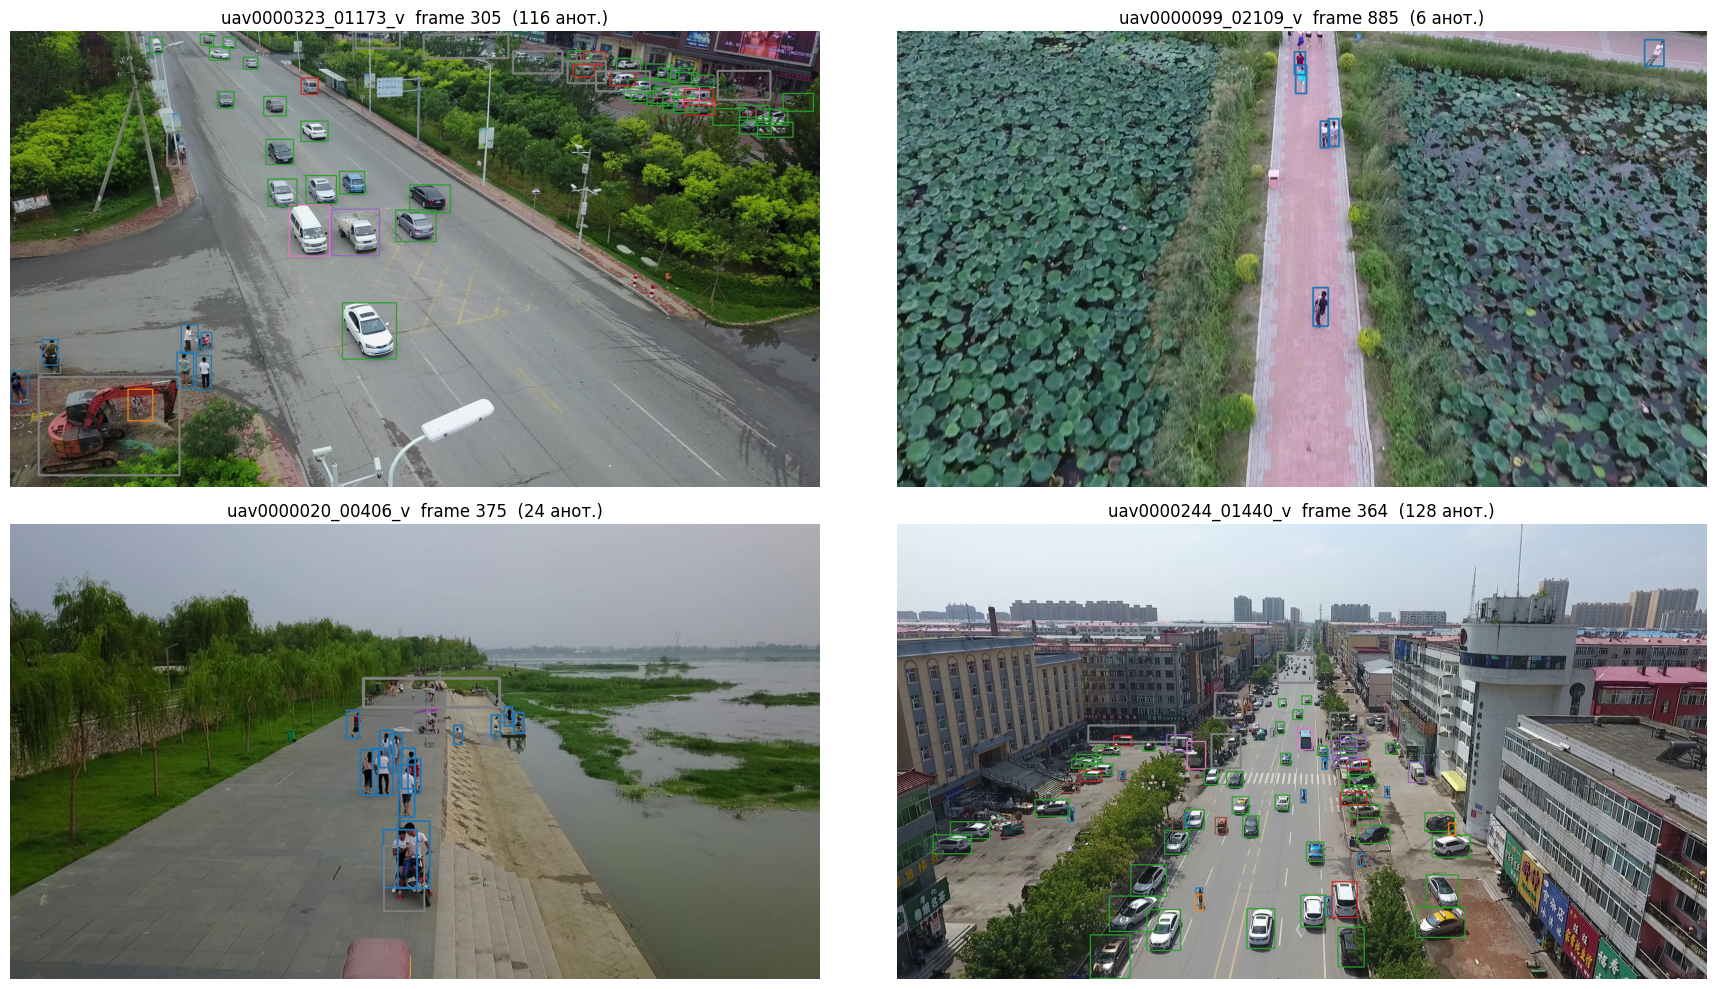

In [ ]:
import cv2, random
import matplotlib.pyplot as plt

COLORS = plt.cm.tab10.colors

def show_frame(split, imgs, anns, image_id, ax):
    row = imgs[imgs['id'] == image_id].iloc[0]
    img = cv2.cvtColor(cv2.imread(f"{ROOT}/{split}/{row['file_name']}"), cv2.COLOR_BGR2RGB)
    for _, a in anns[anns['image_id'] == image_id].iterrows():
        x, y, w, h = a['bbox']
        if a['iscrowd'] == 1:
            cv2.rectangle(img, (int(x), int(y)), (int(x+w), int(y+h)), (128, 128, 128), 3)
        else:
            c = tuple(int(v * 255) for v in COLORS[a['category_id'] - 1])
            cv2.rectangle(img, (int(x), int(y)), (int(x+w), int(y+h)), c, 2)
    ax.imshow(img)
    ax.set_title(f"{row['video']}  frame {row['frame_id']}  ({len(anns[anns['image_id']==image_id])} анот.)")
    ax.axis('off')

random.seed(42)
ids = random.sample(list(train_imgs['id']), 4)
fig, axs = plt.subplots(2, 2, figsize=(18, 10))
for ax, i in zip(axs.ravel(), ids):
    show_frame('train', train_imgs, train_anns, i, ax)
plt.tight_layout()
plt.show()

Перевіряю, наскільки ігноровані зони (iscrowd=1) перетинаються зі звичайними об'єктами.
~1.3% об'єктів більше ніж наполовину лежать у зоні. Ігноровані зони заливаю сірим (114), а об'єкти з IoA > 0.5 викидаю з таргетів. Так модель не вчиться на «шумі» в зонах, де розмітки немає, і ми майже нічого не втрачаємо.

In [ ]:
SEED = 42

def ioa_with_zones(objs, zones):
    o = np.asarray(objs, float); z = np.asarray(zones, float)
    ox1, oy1, ox2, oy2 = o[:,0], o[:,1], o[:,0]+o[:,2], o[:,1]+o[:,3]
    zx1, zy1, zx2, zy2 = z[:,0], z[:,1], z[:,0]+z[:,2], z[:,1]+z[:,3]
    iw = np.clip(np.minimum(ox2[:,None], zx2[None]) - np.maximum(ox1[:,None], zx1[None]), 0, None)
    ih = np.clip(np.minimum(oy2[:,None], zy2[None]) - np.maximum(oy1[:,None], zy1[None]), 0, None)
    return ((iw*ih) / (o[:,2]*o[:,3])[:,None]).max(axis=1)

rng = np.random.default_rng(SEED)
sample_ids = rng.choice(train_imgs['id'].values, 3000, replace=False)
sub = train_anns[train_anns['image_id'].isin(sample_ids)]

res = []
for iid, g in sub.groupby('image_id'):
    z = g[g['iscrowd'] == 1]['bbox'].tolist()
    o = g[g['iscrowd'] == 0]['bbox'].tolist()
    if z and o:
        res.append(ioa_with_zones(o, z))

ioa = np.concatenate(res)
print('кадрів із зонами та об\'єктами:', len(res))
print('об\'єктів проаналізовано:', len(ioa))
print('IoA > 0.5 (більша частина об\'єкта в зоні):', round((ioa > 0.5).mean(), 4))
print('IoA > 0.9 (майже повністю в зоні):', round((ioa > 0.9).mean(), 4))

кадрів із зонами та об'єктами: 2206
об'єктів проаналізовано: 105498
IoA > 0.5 (більша частина об'єкта в зоні): 0.0134
IoA > 0.9 (майже повністю в зоні): 0.0085


# Faster-RCNN

In [ ]:
import random, json, time, os
import numpy as np
import pandas as pd
import torch
import torchvision

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch:', torch.__version__)
print('torchvision:', torchvision.__version__)
print('device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM, ГБ:', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

torch: 2.14.1+cu130
torchvision: 0.29.1+cu130
device: cuda
GPU: Tesla T4
VRAM, ГБ: 15.6


Додаю базові аугментації: горизонтальний фліп, невеликий scale 0.8, 1.25, зміна яскравості. Також беру кожен 3-й кадр (FRAME_STEP=3)

In [ ]:
!pip -q install -U albumentations
import albumentations as A
import cv2
from torch.utils.data import Dataset, DataLoader

IMG_SIZE = 1024
GRAY = 114

def ioa_boxes(objs, zones):
    o = np.asarray(objs, float); z = np.asarray(zones, float)
    iw = np.clip(np.minimum((o[:,0]+o[:,2])[:,None], (z[:,0]+z[:,2])[None])
                 - np.maximum(o[:,0][:,None], z[:,0][None]), 0, None)
    ih = np.clip(np.minimum((o[:,1]+o[:,3])[:,None], (z[:,1]+z[:,3])[None])
                 - np.maximum(o[:,1][:,None], z[:,1][None]), 0, None)
    return ((iw*ih) / (o[:,2]*o[:,3])[:,None]).max(axis=1)

TRAIN_AUG = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.Affine(scale=(0.8, 1.25), translate_percent=(-0.1, 0.1),
                 fit_output=False, border_mode=cv2.BORDER_CONSTANT,
                 fill=GRAY, p=0.5),
        A.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.3, hue=0.0, p=0.8),
    ],
    bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels'],
                             min_visibility=0.4, min_area=16),
)

class VisDroneDet(Dataset):
    def __init__(self, split, imgs, anns, frame_step=1, train=False):
        self.split, self.train = split, train
        imgs = imgs.sort_values(['video', 'frame_id'])
        imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])
        self.imgs = imgs.reset_index(drop=True)
        self.by_img = {k: g for k, g in anns.groupby('image_id')}

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        row = self.imgs.iloc[i]
        img = cv2.cvtColor(cv2.imread(f"{ROOT}/{self.split}/{row['file_name']}"), cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]

        g = self.by_img.get(row['id'])
        boxes = np.zeros((0, 4), np.float32); labels = np.zeros((0,), np.int64)
        if g is not None:
            zones = g[g['iscrowd'] == 1]['bbox'].tolist()
            objs = g[g['iscrowd'] == 0]
            ob = objs['bbox'].tolist()
            lb = objs['category_id'].values
            if zones:
                for x, y, w, h in zones:
                    img[int(y):int(y+h), int(x):int(x+w)] = GRAY
                if ob:
                    keep = ioa_boxes(ob, zones) <= 0.5
                    ob = [b for b, k in zip(ob, keep) if k]; lb = lb[keep]
            if ob:
                b = np.asarray(ob, np.float32)
                boxes = np.stack([b[:,0], b[:,1], b[:,0]+b[:,2], b[:,1]+b[:,3]], 1)
                labels = lb.astype(np.int64)

        s = IMG_SIZE / max(H, W)
        img = cv2.resize(img, (round(W*s), round(H*s)), interpolation=cv2.INTER_AREA)
        boxes = boxes * s
        nh, nw = img.shape[:2]

        if self.train:
            boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, nw)
            boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, nh)
            ok = ((boxes[:, 2] - boxes[:, 0]) > 1) & ((boxes[:, 3] - boxes[:, 1]) > 1)
            boxes, labels = boxes[ok], labels[ok]
            out = TRAIN_AUG(image=img, bboxes=boxes.tolist(), labels=labels.tolist())
            img = out['image']
            boxes = np.asarray(out['bboxes'], np.float32).reshape(-1, 4)
            labels = np.asarray(out['labels'], np.int64)

        t = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float() / 255.0
        target = {'boxes': torch.from_numpy(boxes).float().reshape(-1, 4),
                  'labels': torch.from_numpy(labels),
                  'image_id': int(row['id']), 'scale': s}
        return t, target

def collate(b):
    return tuple(zip(*b))

In [ ]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

FRAME_STEP = 3
SEED = 42

train_ds = VisDroneDet('train', train_imgs, train_anns, frame_step=FRAME_STEP, train=True)
val_ds   = VisDroneDet('val',   val_imgs,   val_anns,   frame_step=1, train=False)
print('train кадрів:', len(train_ds), '| val кадрів:', len(val_ds))

def seed_worker(worker_id):
    s = SEED + worker_id
    np.random.seed(s); random.seed(s)

g = torch.Generator(); g.manual_seed(SEED)

def build_model(rpn_post_nms_train=2000, rpn_post_nms_test=1000,
                box_batch_size=512, box_pos_frac=0.25):
    m = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
        min_size=576, max_size=1024,                  # вхід = наш 1024x576
        rpn_post_nms_top_n_train=rpn_post_nms_train,  # параметр 1: кількість пропозицій
        rpn_post_nms_top_n_test=rpn_post_nms_test,
        box_batch_size_per_image=box_batch_size,      # параметр 2: RoI sampling
        box_positive_fraction=box_pos_frac,
        box_detections_per_img=300,                   # до 180 об'єктів на кадр
    )
    in_f = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(in_f, 9)   # 8 класів + фон
    return m

/tmp/ipykernel_4783/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])


train кадрів: 8090 | val кадрів: 2846


/tmp/ipykernel_4783/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])


In [ ]:
from torch.utils.data import Subset

train_eval_ds = VisDroneDet('train', train_imgs, train_anns, frame_step=3, train=False)
rng = np.random.default_rng(SEED)
idx = rng.choice(len(train_eval_ds), 1500, replace=False)
train_eval_dl = DataLoader(Subset(train_eval_ds, idx), batch_size=8, shuffle=False,
                           num_workers=2, collate_fn=collate)

/tmp/ipykernel_4783/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])


In [ ]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import io, contextlib

with contextlib.redirect_stdout(io.StringIO()):
    val_gt = COCO(f'{ROOT}/val/annotations_coco.json')
    train_gt = COCO(f'{ROOT}/train/annotations_coco.json')

def ap_from_eval(E, iou=None, area='all', cls=None):
    p = E.eval['precision']
    a = {'all': 0, 'small': 1, 'medium': 2, 'large': 3}[area]
    p = p[:, :, :, a, -1]
    if cls is not None:
        p = p[:, :, cls:cls+1]
    if iou is not None:
        t = int(np.where(np.isclose(E.params.iouThrs, iou))[0][0])
        p = p[t:t+1]
    p = p[p > -1]
    return float(p.mean()) if p.size else float('nan')

@torch.no_grad()
def evaluate(model, dl, ds, max_batches=None, gt=None):
    gt = gt if gt is not None else val_gt
    model.eval()
    results, img_ids = [], []
    t_inf, n_img = 0.0, 0
    for bi, (imgs, tgts) in enumerate(dl):
        if max_batches and bi >= max_batches:
            break
        imgs_d = [i.to(device) for i in imgs]
        torch.cuda.synchronize(); t0 = time.time()
        with torch.autocast('cuda'):
            outs = model(imgs_d)
        torch.cuda.synchronize(); t_inf += time.time() - t0
        n_img += len(imgs)
        for o, t in zip(outs, tgts):
            s = t['scale']; iid = t['image_id']; img_ids.append(iid)
            b = o['boxes'].float().cpu().numpy() / s
            for (x1, y1, x2, y2), sc, lb in zip(b, o['scores'].float().cpu().numpy(), o['labels'].cpu().numpy()):
                results.append({'image_id': iid, 'category_id': int(lb),
                                'bbox': [float(x1), float(y1), float(x2-x1), float(y2-y1)],
                                'score': float(sc)})
    fps = n_img / max(t_inf, 1e-9)
    if not results:
        return {'mAP': 0, 'AP50': 0, 'AP_small': 0, 'fps': fps}
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(results)
        E = COCOeval(gt, dt, 'bbox')
        E.params.imgIds = img_ids
        E.params.maxDets = [1, 10, 300]
        E.evaluate(); E.accumulate()
    return {'mAP': ap_from_eval(E),
            'AP50': ap_from_eval(E, iou=0.5),
            'AP_small': ap_from_eval(E, area='small'),
            'fps': fps, 'eval': E}

In [ ]:
import math
import os

CKPT_DIR = '/content/drive/MyDrive/visdrone_ckpt'
os.makedirs(CKPT_DIR, exist_ok=True)

BATCH = 8
EPOCHS = 3
LR = 0.01
WARMUP_ITERS = 300

g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2,
                      collate_fn=collate, worker_init_fn=seed_worker, generator=g)
val_dl = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2, collate_fn=collate)

def train_model(model, name, epochs=EPOCHS, lr=LR):
    model.to(device).train()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda')

    total_iters = epochs * len(train_dl)

    def lr_at(it):
        if it < WARMUP_ITERS:
            return lr * (0.001 + 0.999 * it / WARMUP_ITERS)
        p = (it - WARMUP_ITERS) / max(1, total_iters - WARMUP_ITERS)
        return lr * 0.5 * (1 + math.cos(math.pi * p))

    it = 0
    history = []
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        run = {}
        for imgs, tgts in train_dl:
            for gr in opt.param_groups:
                gr['lr'] = lr_at(it)
            imgs = [i.to(device) for i in imgs]
            tgts = [{'boxes': t['boxes'].to(device), 'labels': t['labels'].to(device)} for t in tgts]

            with torch.autocast('cuda'):
                losses = model(imgs, tgts)
                loss = sum(losses.values())

            if not torch.isfinite(loss):
                print('нескінченний loss, пропускаю ітерацію', it)
                opt.zero_grad(); it += 1
                continue

            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 10.0)
            scaler.step(opt); scaler.update()

            for k, v in losses.items():
                run[k] = run.get(k, 0) + v.item()
            it += 1
            if it % 50 == 0:
                n = 50
                print(f'ep {ep+1} it {it}/{total_iters} lr {lr_at(it):.5f} | ' +
                      ' '.join(f'{k[5:]}={run[k]/n:.3f}' for k in run) +
                      f' | {time.time()-t0:.0f}s')
                history.append({'it': it, **{k: run[k]/n for k in run}})
                run = {}

        path = f'{CKPT_DIR}/{name}_ep{ep+1}.pt'
        torch.save({'model': model.state_dict(), 'epoch': ep + 1}, path)
        print(f'епоха {ep+1} завершена за {(time.time()-t0)/60:.1f} хв, збережено {path}')
        r = evaluate(model, val_dl, val_ds)
        print(f"  VAL ep{ep+1}: mAP={r['mAP']:.3f} AP50={r['AP50']:.3f} "
              f"AP_small={r['AP_small']:.3f} fps={r['fps']:.1f}")
        rt = evaluate(model, train_eval_dl, train_eval_ds, gt=train_gt)
        print(f"  TRAIN ep{ep+1}: mAP={rt['mAP']:.3f} AP50={rt['AP50']:.3f}"
              f"AP_small={rt['AP_small']:.3f} fps={rt['fps']:.1f}")
        model.train()
    return history


In [ ]:
model = build_model().to(device)
hist_base = train_model(model, 'frcnn_v2_baseline')

ep 1 it 50/3036 lr 0.00168 | classifier=1.283 box_reg=0.617 objectness=0.742 rpn_box_reg=0.221 | 57s
ep 1 it 100/3036 lr 0.00334 | classifier=0.460 box_reg=0.559 objectness=0.137 rpn_box_reg=0.161 | 112s
ep 1 it 150/3036 lr 0.00500 | classifier=0.385 box_reg=0.479 objectness=0.110 rpn_box_reg=0.150 | 167s
ep 1 it 200/3036 lr 0.00667 | classifier=0.348 box_reg=0.450 objectness=0.102 rpn_box_reg=0.142 | 221s
ep 1 it 250/3036 lr 0.00834 | classifier=0.313 box_reg=0.421 objectness=0.089 rpn_box_reg=0.136 | 276s
ep 1 it 300/3036 lr 0.01000 | classifier=0.305 box_reg=0.413 objectness=0.086 rpn_box_reg=0.134 | 330s
ep 1 it 350/3036 lr 0.00999 | classifier=0.283 box_reg=0.400 objectness=0.077 rpn_box_reg=0.127 | 384s
ep 1 it 400/3036 lr 0.00997 | classifier=0.283 box_reg=0.395 objectness=0.073 rpn_box_reg=0.127 | 439s
ep 1 it 450/3036 lr 0.00993 | classifier=0.257 box_reg=0.384 objectness=0.071 rpn_box_reg=0.121 | 493s
ep 1 it 500/3036 lr 0.00987 | classifier=0.255 box_reg=0.378 objectness=0.0

In [ ]:
val_ds_full = VisDroneDet('val', val_imgs, val_anns, frame_step=1, train=False)
val_dl_full = DataLoader(val_ds_full, batch_size=8, shuffle=False,
                         num_workers=2, collate_fn=collate)

/tmp/ipykernel_4783/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])


In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_model().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_baseline_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:02<00:00, 66.0MB/s]


,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.385,0.194,0.699,0.397,0.276,0.103,0.190
2,0.449,0.204,0.779,0.409,0.322,0.099,0.245
3,0.472,0.204,0.796,0.405,0.346,0.101,0.268


Baseline Faster R-CNN: на третій епосі val вже не росте, а train продовжує рости (0.449 → 0.472), і розрив train/val збільшується до 0.27. Тобто модель уже почала перенавчатися

### Вплив кількості RPN-пропозицій

In [ ]:
model_rpn1000 = build_model(rpn_post_nms_train=1000, rpn_post_nms_test=1000).to(device)
hist_rpn1000 = train_model(model_rpn1000, 'frcnn_v2_rpn_train1000')

ep 1 it 50/3036 lr 0.00168 | classifier=1.262 box_reg=0.565 objectness=0.802 rpn_box_reg=0.239 | 56s
ep 1 it 100/3036 lr 0.00334 | classifier=0.520 box_reg=0.542 objectness=0.144 rpn_box_reg=0.165 | 110s
ep 1 it 150/3036 lr 0.00500 | classifier=0.445 box_reg=0.482 objectness=0.110 rpn_box_reg=0.148 | 164s
ep 1 it 200/3036 lr 0.00667 | classifier=0.409 box_reg=0.450 objectness=0.097 rpn_box_reg=0.134 | 217s
ep 1 it 250/3036 lr 0.00834 | classifier=0.387 box_reg=0.422 objectness=0.091 rpn_box_reg=0.140 | 272s
ep 1 it 300/3036 lr 0.01000 | classifier=0.364 box_reg=0.414 objectness=0.085 rpn_box_reg=0.130 | 325s
ep 1 it 350/3036 lr 0.00999 | classifier=0.352 box_reg=0.414 objectness=0.080 rpn_box_reg=0.127 | 379s
ep 1 it 400/3036 lr 0.00997 | classifier=0.336 box_reg=0.395 objectness=0.074 rpn_box_reg=0.124 | 433s
ep 1 it 450/3036 lr 0.00993 | classifier=0.330 box_reg=0.387 objectness=0.072 rpn_box_reg=0.125 | 487s
ep 1 it 500/3036 lr 0.00987 | classifier=0.332 box_reg=0.396 objectness=0.0

In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_model().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_rpn_train1000_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.393,0.204,0.715,0.405,0.267,0.102,0.189
2,0.464,0.210,0.788,0.409,0.345,0.111,0.255
3,0.481,0.202,0.803,0.393,0.362,0.108,0.279


rpn_post_nms_top_n_train = 2000 і 1000 дають однакову якість (mAP ≈ 0.20, AP50 ≈ 0.40, AP_small ≈ 0.10), різниця в межах шуму;
val mAP досягає піку на 2-й епосі (0.210) і потім падає до 0.202, тобто перенавчання видно ще раніше.

### Зміна відсотку позитивів

In [ ]:
model_pos05 = build_model(box_batch_size=512, box_pos_frac=0.5).to(device)
hist_pos05 = train_model(model_pos05, 'frcnn_v2_roi512_pos050')

ep 1 it 50/3036 lr 0.00168 | classifier=1.325 box_reg=0.944 objectness=0.766 rpn_box_reg=0.222 | 51s
ep 1 it 100/3036 lr 0.00334 | classifier=0.593 box_reg=0.869 objectness=0.138 rpn_box_reg=0.161 | 106s
ep 1 it 150/3036 lr 0.00500 | classifier=0.518 box_reg=0.833 objectness=0.117 rpn_box_reg=0.149 | 160s
ep 1 it 200/3036 lr 0.00667 | classifier=0.431 box_reg=0.745 objectness=0.095 rpn_box_reg=0.140 | 214s
ep 1 it 250/3036 lr 0.00834 | classifier=0.400 box_reg=0.709 objectness=0.089 rpn_box_reg=0.136 | 268s
ep 1 it 300/3036 lr 0.01000 | classifier=0.385 box_reg=0.708 objectness=0.076 rpn_box_reg=0.128 | 322s
ep 1 it 350/3036 lr 0.00999 | classifier=0.374 box_reg=0.703 objectness=0.084 rpn_box_reg=0.128 | 376s
ep 1 it 400/3036 lr 0.00997 | classifier=0.350 box_reg=0.675 objectness=0.077 rpn_box_reg=0.127 | 430s
ep 1 it 450/3036 lr 0.00993 | classifier=0.332 box_reg=0.676 objectness=0.069 rpn_box_reg=0.121 | 485s
ep 1 it 500/3036 lr 0.00987 | classifier=0.333 box_reg=0.682 objectness=0.0

In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_model().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_roi512_pos050_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.396,0.185,0.724,0.374,0.270,0.088,0.211
2,0.469,0.200,0.804,0.393,0.344,0.095,0.269
3,0.491,0.201,0.818,0.391,0.367,0.099,0.290


Збільшення частки позитивів box_pos_frac з 0.25 до 0.5 трохи погіршило результат (mAP 0.201 проти 0.204, AP50 0.391 проти 0.405), імовірно через те, що у вибірку потрапляє більше слабких позитивних RoI (IoU близько 0.5) за рахунок фону. Модель менше вчиться відрізняти об'єкти від фону, а регресія боксу навчається на менш точних прикладах.

### Аналіз найгірших випадків

In [ ]:
model = build_model().to(device)
model.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_baseline_ep3.pt', map_location=device)['model'])
model.eval()

dets = {}
with torch.no_grad():
    for imgs, tgts in val_dl_full:
        with torch.autocast('cuda'):
            outs = model([i.to(device) for i in imgs])
        for o, t in zip(outs, tgts):
            dets[t['image_id']] = (o['boxes'].float().cpu().numpy() / t['scale'],
                                   o['scores'].float().cpu().numpy(),
                                   o['labels'].cpu().numpy())
print('кадрів з детекціями:', len(dets))

кадрів з детекціями: 2846


In [ ]:
results = []
for iid, (b, s, l) in dets.items():
    for (x1, y1, x2, y2), sc, lb in zip(b, s, l):
        results.append({'image_id': iid, 'category_id': int(lb),
                        'bbox': [float(x1), float(y1), float(x2-x1), float(y2-y1)],
                        'score': float(sc)})

with contextlib.redirect_stdout(io.StringIO()):
    dt = val_gt.loadRes(results)
    E = COCOeval(val_gt, dt, 'bbox')
    E.params.imgIds = list(dets.keys())
    E.params.maxDets = [1, 10, 300]
    E.evaluate(); E.accumulate()

rows = []
for k, name in enumerate(CLASSES):
    rows.append({'class': name,
                 'AP': ap_from_eval(E, cls=k),
                 'AP50': ap_from_eval(E, iou=0.5, cls=k),
                 'AP_small': ap_from_eval(E, area='small', cls=k)})
pd.DataFrame(rows).set_index('class').round(3)

,AP,AP50,AP_small
class,,,
person,0.263,0.634,0.110
bicycle,0.185,0.399,0.001
car,0.368,0.600,0.205
van,0.233,0.400,0.165
truck,0.224,0.388,0.032
tricycle,0.195,0.433,0.108
bus,0.052,0.062,NaN
motor,0.112,0.321,0.084


Модель найкраще виявляє car (AP = 0.368), тоді як найнижчий AP у bus (0.052). Високі AP50 для person і car свідчать, що модель часто знаходить об’єкти, але точність локалізації знижується за суворіших IoU-порогів. Для малих об’єктів результати слабкі, особливо для bicycle (AP_small = 0.001) і truck (0.032).

In [ ]:
clip_of = dict(zip(val_imgs['id'], val_imgs['video']))
rows = []
for clip in sorted(set(clip_of.values())):
    ids = [i for i in dets if clip_of[i] == clip]
    with contextlib.redirect_stdout(io.StringIO()):
        E2 = COCOeval(val_gt, dt, 'bbox')
        E2.params.imgIds = ids
        E2.params.maxDets = [1, 10, 300]
        E2.evaluate(); E2.accumulate()
    n_gt = sum(1 for a in val_anns[(val_anns['image_id'].isin(ids)) & (val_anns['iscrowd'] == 0)].index)
    rows.append({'clip': clip, 'frames': len(ids),
                 'obj_per_frame': round(n_gt / len(ids), 1),
                 'AP': ap_from_eval(E2), 'AP50': ap_from_eval(E2, iou=0.5)})
pd.DataFrame(rows).set_index('clip').round(3)

,frames,obj_per_frame,AP,AP50
clip,,,,
uav0000086_00000_v,464,49.8,0.176,0.443
uav0000117_02622_v,349,49.5,0.235,0.459
uav0000137_00458_v,233,103.4,0.280,0.570
uav0000182_00000_v,363,48.7,0.170,0.384
uav0000268_05773_v,978,13.9,0.117,0.193
uav0000305_00000_v,184,34.7,0.208,0.308
uav0000339_00001_v,275,43.7,0.236,0.450


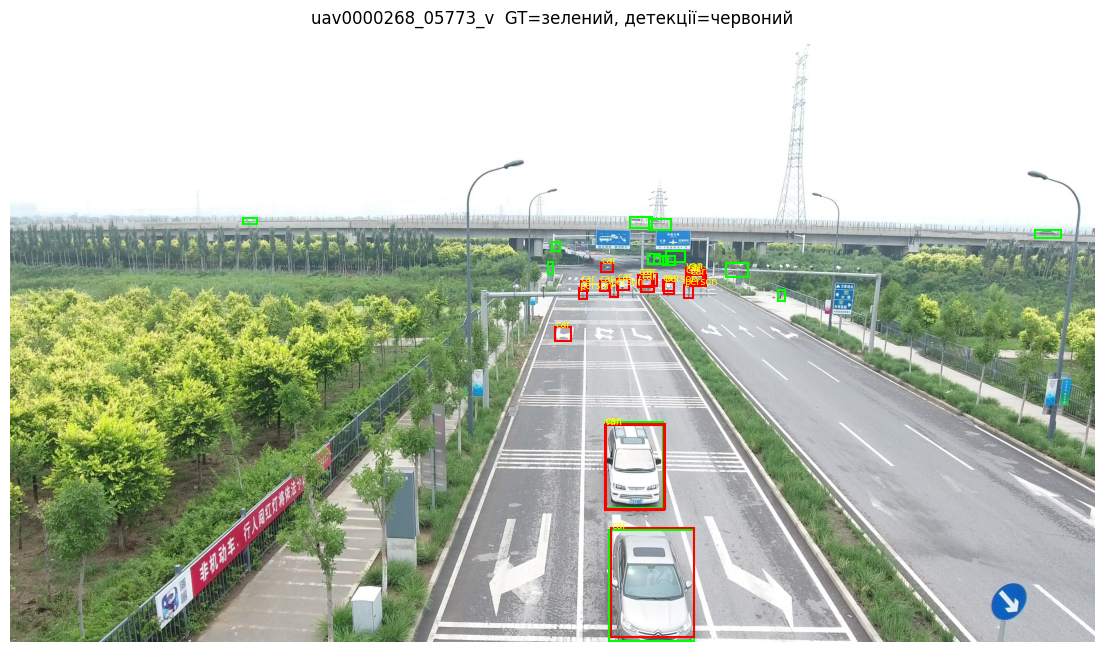

In [ ]:
import matplotlib.pyplot as plt, matplotlib.patches as pa

def show(iid, thr=0.1):
    row = val_imgs[val_imgs['id'] == iid].iloc[0]
    img = cv2.cvtColor(cv2.imread(f"{ROOT}/val/{row['file_name']}"), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(figsize=(14, 8)); ax.imshow(img); ax.axis('off')
    for _, a in val_anns[(val_anns['image_id'] == iid) & (val_anns['iscrowd'] == 0)].iterrows():
        x, y, w, h = a['bbox']
        ax.add_patch(pa.Rectangle((x, y), w, h, fill=False, ec='lime', lw=1.5))
    b, s, l = dets[iid]
    for (x1, y1, x2, y2), sc, lb in zip(b, s, l):
        if sc > thr:
            ax.add_patch(pa.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec='red', lw=1.5))
            ax.text(x1, y1, CLASSES[lb-1], color='yellow', fontsize=7)
    ax.set_title(f"{row['video']}  GT=зелений, детекції=червоний")
    plt.show()

# кадр з найгіршого кліпу
iid = val_imgs[val_imgs['video'] == 'uav0000268_05773_v']['id'].iloc[400]
show(iid)

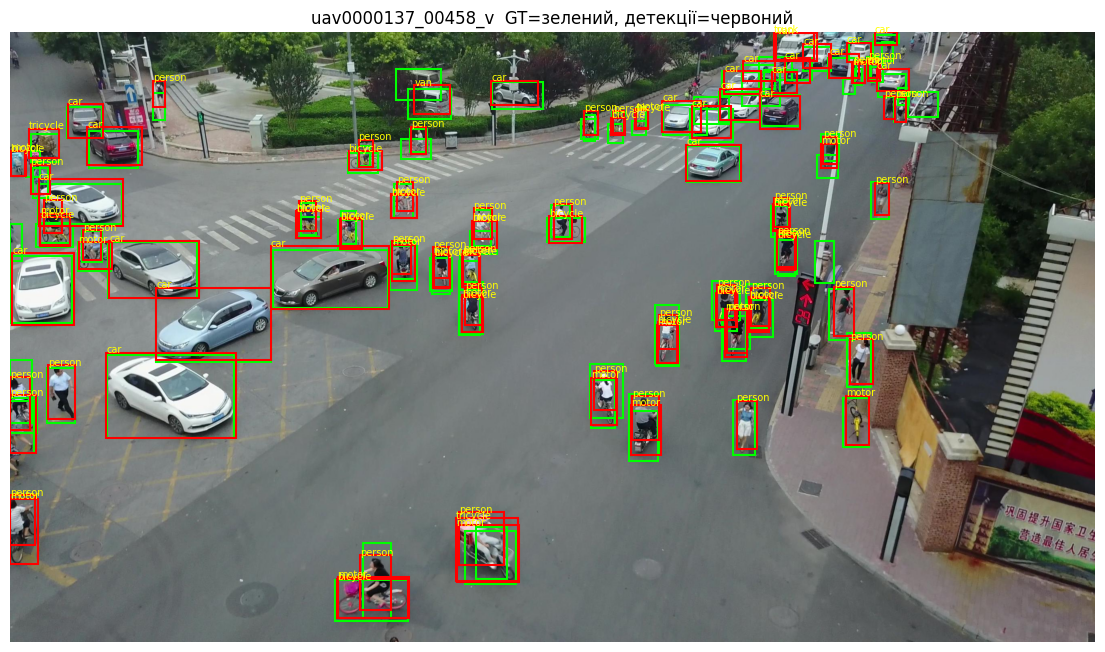

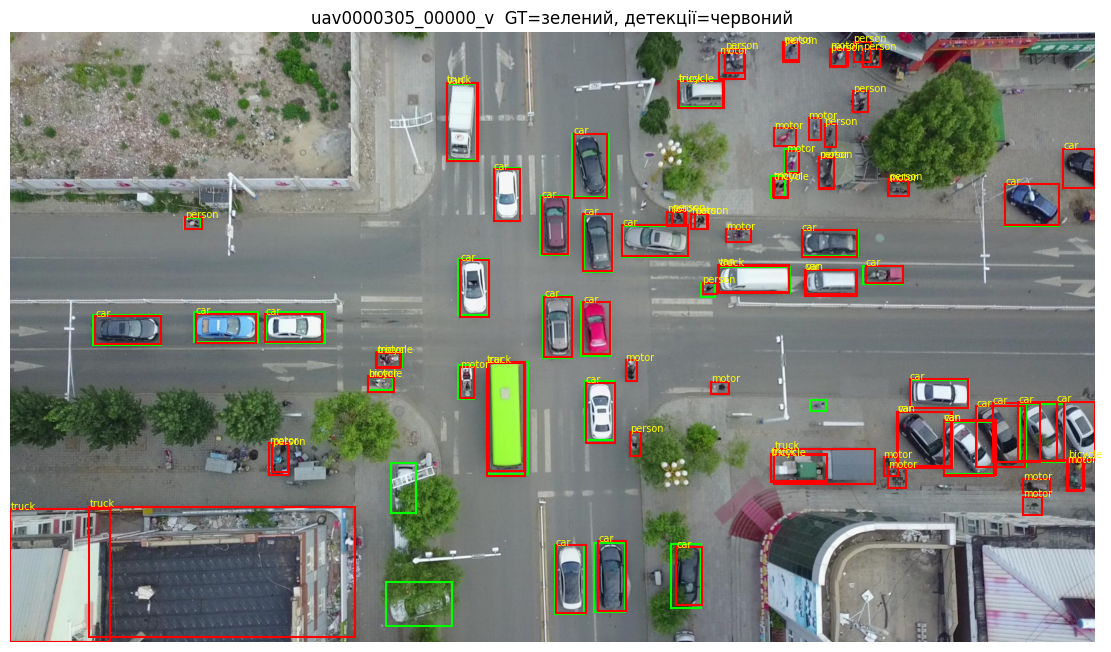

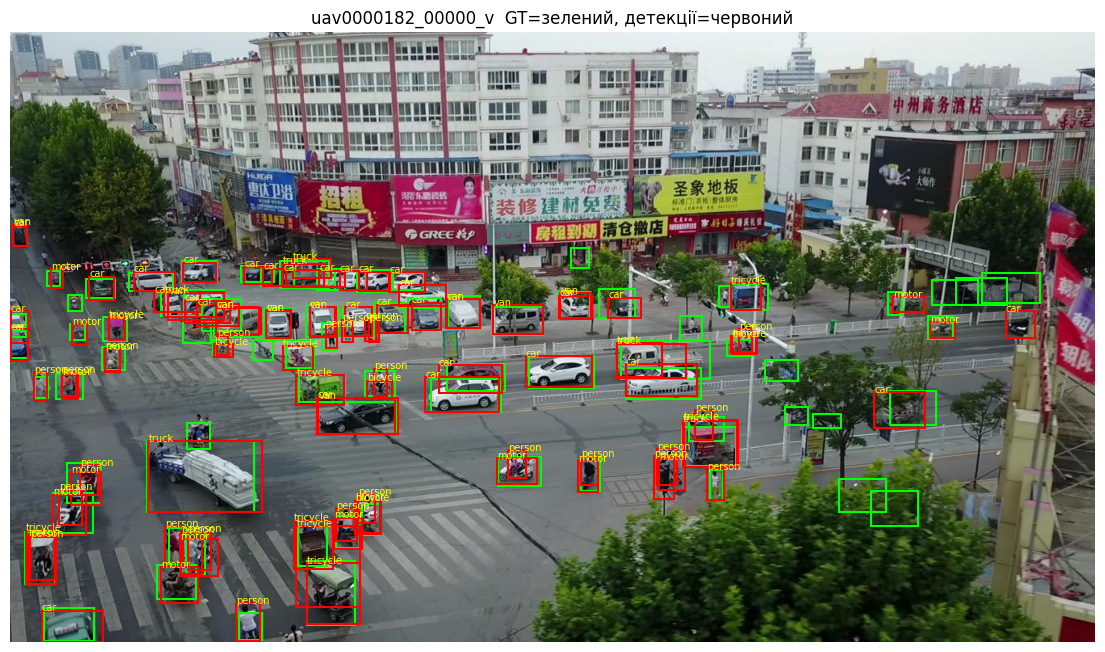

In [ ]:
def pick(cat):
    g = val_anns[(val_anns['category_id'] == cat) & (val_anns['iscrowd'] == 0)]
    return g['image_id'].value_counts().index[0]

vid = val_imgs[val_imgs['video'] == 'uav0000268_05773_v']['id']

show(pick(2))
show(pick(7))
show(pick(8))

Кадр з bicycle (uav0000137): дуже щільне перехрестя з велосипедистами, і загалом модель справляється добре, майже всі люди й машини знайдені. Але видно типову проблему: на кожному велосипедисті є два бокси, person і bicycle, і поверх них модель часто ставить ще й motor. Зверху велосипед і мопед виглядають майже однаково, тому bicycle/motor плутаються, і через це в bicycle такий низький AP.

Кадр з bus (uav0000305): вигляд строго згори. Зелений автобус по центру модель назвала truck. Ще хибні детекції truck на дахах будівель знизу зліва: великі прямокутні дахи модель приймає за кузови. А машину, наполовину сховану деревом, модель пропустила.

Кадр з motor (uav0000182): похилий кадр з дуже щільною вулицею. Мотоцикли з людьми й трицикли переважно знайдені, але пропуски є там, де об'єкти частково закриті деревами.

# RetinaNet

In [ ]:
import torch.nn as nn
from torchvision.models.detection import retinanet_resnet50_fpn_v2, RetinaNet_ResNet50_FPN_V2_Weights

def build_retina(score_thresh=0.05, nms_thresh=0.5, fg_iou=0.5, bg_iou=0.4):
    m = retinanet_resnet50_fpn_v2(
        weights=RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1,
        min_size=576, max_size=1024,
        score_thresh=score_thresh,
        nms_thresh=nms_thresh,
        detections_per_img=300,
        fg_iou_thresh=fg_iou, bg_iou_thresh=bg_iou,
    )

    h = m.head.classification_head
    h.num_classes = 9
    h.cls_logits = nn.Conv2d(256, h.num_anchors * 9, 3, padding=1)
    nn.init.normal_(h.cls_logits.weight, std=0.01)
    nn.init.constant_(h.cls_logits.bias, -math.log((1 - 0.01) / 0.01))
    return m

torch.manual_seed(SEED)
retina = build_retina().to(device)
print('параметрів, млн:', round(sum(p.numel() for p in retina.parameters()) / 1e6, 1))
print('якорів на позицію:', retina.head.classification_head.num_anchors)
print('розміри якорів:', retina.anchor_generator.sizes)
print('співвідношення:', retina.anchor_generator.aspect_ratios[0])

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 168MB/s]


параметрів, млн: 36.5
якорів на позицію: 9
розміри якорів: ((32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406), (512, 645, 812))
співвідношення: (0.5, 1.0, 2.0)


In [ ]:
torch.manual_seed(SEED)
g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2,
                      collate_fn=collate, worker_init_fn=seed_worker, generator=g)

retina = build_retina().to(device)
hist_retina = train_model(retina, 'retina_v2_baseline', lr=0.005)

ep 1 it 50/3036 lr 0.00084 | ification=1.129 regression=0.313 | 42s
ep 1 it 100/3036 lr 0.00167 | ification=1.057 regression=0.317 | 76s
ep 1 it 150/3036 lr 0.00250 | ification=0.835 regression=0.304 | 112s
ep 1 it 200/3036 lr 0.00334 | ification=0.577 regression=0.292 | 147s
ep 1 it 250/3036 lr 0.00417 | ification=0.449 regression=0.287 | 182s
ep 1 it 300/3036 lr 0.00500 | ification=0.398 regression=0.295 | 217s
ep 1 it 350/3036 lr 0.00500 | ification=0.353 regression=0.284 | 252s
ep 1 it 400/3036 lr 0.00498 | ification=0.331 regression=0.282 | 287s
ep 1 it 450/3036 lr 0.00496 | ification=0.311 regression=0.285 | 323s
ep 1 it 500/3036 lr 0.00493 | ification=0.299 regression=0.282 | 357s
ep 1 it 550/3036 lr 0.00490 | ification=0.283 regression=0.276 | 393s
ep 1 it 600/3036 lr 0.00485 | ification=0.282 regression=0.274 | 428s
ep 1 it 650/3036 lr 0.00480 | ification=0.277 regression=0.281 | 463s
ep 1 it 700/3036 lr 0.00474 | ification=0.262 regression=0.272 | 500s
ep 1 it 750/3036 lr 0.0

In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_retina().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/retina_v2_baseline_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.179,0.136,0.340,0.263,0.047,0.044,0.043
2,0.218,0.142,0.409,0.277,0.065,0.049,0.076
3,0.229,0.150,0.423,0.289,0.075,0.053,0.078


RetinaNet baseline: val mAP 0.150, тобто на 0.054 гірше за Faster R-CNN (0.204). Зате модель працює швидше (25.6 fps проти 17.3).

Розрив train/val маленький (0.078), а val mAP ще росте на кожній епосі (0.136 → 0.142 → 0.150). Тобто RetinaNet за 3 епохи не збіглась і скоріше недонавчена, ніж перенавчена.

In [ ]:
tr['s'] = IMG_SIZE / np.maximum(tr['width'], tr['height'])
tr['w_in'], tr['h_in'] = tr['w'] * tr['s'], tr['h'] * tr['s']

print('розмір об\'єкта на вході (sqrt(w*h)), px:')
print((tr['size'] * tr['s']).quantile([.05, .1, .25, .5, .75, .9, .95]).round(1).to_string())
print('\nмедіана h/w по класах:')
print((tr['h'] / tr['w']).groupby(tr['class']).median().round(2).reindex(CLASSES).to_string())

def anchor_shapes(sizes, ratios=(0.5, 1.0, 2.0)):
    out = []
    for level in sizes:
        for s in level:
            for r in ratios:
                out.append((s / r**0.5, s * r**0.5))
    return np.array(out)

def fit(anchor_sizes, n=200000):
    a = anchor_shapes(anchor_sizes)
    d = tr.sample(n, random_state=SEED)
    w, h = d['w_in'].values[:, None], d['h_in'].values[:, None]
    inter = np.minimum(w, a[:, 0]) * np.minimum(h, a[:, 1])
    iou = inter / (w * h + a[:, 0] * a[:, 1] - inter)
    best = iou.max(axis=1)
    return (best >= 0.5).mean(), (best >= 0.4).mean(), np.median(best)

default = ((32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406), (512, 645, 812))
small   = ((16, 20, 25), (32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406))

for name, sz in [('стандартні', default), ('менші (x0.5)', small)]:
    f5, f4, med = fit(sz)
    print(f'{name}: частка об\'єктів з IoU>=0.5: {f5:.3f} | >=0.4: {f4:.3f} | медіана найкращого IoU: {med:.2f}')

розмір об'єкта на вході (sqrt(w*h)), px:
0.05    10.9
0.10    12.9
0.25    17.3
0.50    24.3
0.75    35.1
0.90    53.0
0.95    66.9

медіана h/w по класах:
class
person      2.00
bicycle     1.06
car         0.80
van         0.90
truck       0.93
tricycle    0.94
bus         0.97
motor       1.24
стандартні: частка об'єктів з IoU>=0.5: 0.554 | >=0.4: 0.641 | медіана найкращого IoU: 0.58
менші (x0.5): частка об'єктів з IoU>=0.5: 0.940 | >=0.4: 0.963 | медіана найкращого IoU: 0.81


Зі стандартними якорями лише 55% об'єктів мають хоча б один якір з IoU ≥ 0.5. Тобто майже половина об'єктів під час навчання взагалі не отримує позитивного якоря, і модель їх просто не вчить. Зі зменшеними вдвічі якорями таких об'єктів 94%.

### Зміна розміру боксів

In [ ]:
from torchvision.models.detection.anchor_utils import AnchorGenerator

def build_retina(anchor_sizes=None, score_thresh=0.05, nms_thresh=0.5, fg_iou=0.5, bg_iou=0.4):
    m = retinanet_resnet50_fpn_v2(
        weights=RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1,
        min_size=576, max_size=1024,
        score_thresh=score_thresh, nms_thresh=nms_thresh, detections_per_img=300,
        fg_iou_thresh=fg_iou, bg_iou_thresh=bg_iou,
    )
    if anchor_sizes is not None:
        m.anchor_generator = AnchorGenerator(anchor_sizes, ((0.5, 1.0, 2.0),) * len(anchor_sizes))
    h = m.head.classification_head
    h.num_classes = 9
    h.cls_logits = nn.Conv2d(256, h.num_anchors * 9, 3, padding=1)
    nn.init.normal_(h.cls_logits.weight, std=0.01)
    nn.init.constant_(h.cls_logits.bias, -math.log((1 - 0.01) / 0.01))
    return m
SMALL = ((16, 20, 25), (32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406))

In [ ]:
SMALL = ((16, 20, 25), (32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406))
retina_A = build_retina(anchor_sizes=SMALL)
hist_A = train_model(retina_A, 'retina_v2_anchors_small', lr=0.005)

ep 1 it 50/3036 lr 0.00084 | ification=1.128 regression=0.548 | 35s
ep 1 it 100/3036 lr 0.00167 | ification=1.070 regression=0.501 | 68s
ep 1 it 150/3036 lr 0.00250 | ification=0.945 regression=0.452 | 102s
ep 1 it 200/3036 lr 0.00334 | ification=0.675 regression=0.413 | 136s
ep 1 it 250/3036 lr 0.00417 | ification=0.617 regression=0.383 | 169s
ep 1 it 300/3036 lr 0.00500 | ification=0.455 regression=0.352 | 202s
ep 1 it 350/3036 lr 0.00500 | ification=0.415 regression=0.331 | 236s
ep 1 it 400/3036 lr 0.00498 | ification=0.387 regression=0.314 | 269s
ep 1 it 450/3036 lr 0.00496 | ification=0.393 regression=0.308 | 302s
ep 1 it 500/3036 lr 0.00493 | ification=0.358 regression=0.302 | 335s
ep 1 it 550/3036 lr 0.00490 | ification=0.351 regression=0.301 | 369s
ep 1 it 600/3036 lr 0.00485 | ification=0.344 regression=0.299 | 402s
ep 1 it 650/3036 lr 0.00480 | ification=0.318 regression=0.291 | 435s
ep 1 it 700/3036 lr 0.00474 | ification=0.329 regression=0.294 | 469s
ep 1 it 750/3036 lr 0.0

In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_retina(anchor_sizes=SMALL).to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/retina_v2_anchors_small_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.135,0.121,0.300,0.265,0.060,0.050,0.014
2,0.175,0.136,0.379,0.294,0.082,0.055,0.040
3,0.184,0.136,0.389,0.293,0.088,0.058,0.047


Зменшення anchors удвічі обґрунтоване розподілом розмірів об’єктів на вході (медіана — 24 px, 5-й перцентиль — 11 px), однак не покращило загальну якість моделі: mAP знизився з 0.150 до 0.136, тоді як AP50 та AP_small майже не змінилися. Імовірно, за три епохи COCO-передтреновані голови не встигли адаптуватися до нових anchors. Отже, основним обмеженням можуть бути роздільність зображень і якість ознак дрібних об’єктів, а не самі anchors.

In [ ]:
def report(path, **kw):
    m = build_retina(**kw).to(device)
    m.load_state_dict(torch.load(path, map_location=device)['model'])
    E = evaluate(m, val_dl_full, val_ds_full)['eval']
    out = {f'AP_{a}': ap_from_eval(E, area=a) for a in ['small', 'medium', 'large']}
    out.update({f'AP_{c}': ap_from_eval(E, cls=k) for k, c in enumerate(CLASSES)})
    del m; torch.cuda.empty_cache()
    return out

rep = {
    'retina_default': report(f'{CKPT_DIR}/retina_v2_baseline_ep3.pt'),
    'retina_small':   report(f'{CKPT_DIR}/retina_v2_anchors_small_ep3.pt', anchor_sizes=SMALL),
}
pd.DataFrame(rep).T.round(3)

Loading and preparing results...
DONE (t=2.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=2.45s)
creating index...
index created!


,AP_small,AP_medium,AP_large,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
retina_default,0.053,0.134,0.288,0.210,0.087,0.332,0.146,0.199,0.140,0.024,0.063
retina_small,0.058,0.124,0.235,0.209,0.106,0.317,0.110,0.155,0.106,0.014,0.073


Падіння mAP майже повністю з великих об'єктів. AP_large впав з 0,288 до 0,235, AP_medium на 0,010, а AP_small навіть трохи виріс. Відповідно, гірші класи це van, truck, tricycle і car, тобто ті, що частіше великі.
Виграли найдрібніші двоколісні: bicycle (+0,019) і motor (+0,010). Тобто малі якорі справді допомогли тим, для кого вони й підбирались, але ці класи мають мало об'єктів і малий внесок у mAP.

In [ ]:
torch.manual_seed(SEED)
g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2,
                      collate_fn=collate, worker_init_fn=seed_worker, generator=g)

retina_B = build_retina(fg_iou=0.4, bg_iou=0.3)
hist_B = train_model(retina_B, 'retina_v2_iou_04_03', lr=0.005)

ep 1 it 50/3036 lr 0.00084 | ification=1.126 regression=0.321 | 35s
ep 1 it 100/3036 lr 0.00167 | ification=1.063 regression=0.318 | 68s
ep 1 it 150/3036 lr 0.00250 | ification=0.847 regression=0.303 | 101s
ep 1 it 200/3036 lr 0.00334 | ification=0.589 regression=0.291 | 135s
ep 1 it 250/3036 lr 0.00417 | ification=0.407 regression=0.290 | 168s
ep 1 it 300/3036 lr 0.00500 | ification=0.352 regression=0.293 | 202s
ep 1 it 350/3036 lr 0.00500 | ification=0.309 regression=0.279 | 235s
ep 1 it 400/3036 lr 0.00498 | ification=0.288 regression=0.279 | 269s
ep 1 it 450/3036 lr 0.00496 | ification=0.267 regression=0.275 | 302s
ep 1 it 500/3036 lr 0.00493 | ification=0.256 regression=0.274 | 336s
ep 1 it 550/3036 lr 0.00490 | ification=0.237 regression=0.269 | 369s
ep 1 it 600/3036 lr 0.00485 | ification=0.236 regression=0.269 | 403s
ep 1 it 650/3036 lr 0.00480 | ification=0.232 regression=0.272 | 436s
ep 1 it 700/3036 lr 0.00474 | ification=0.219 regression=0.262 | 469s
ep 1 it 750/3036 lr 0.0

In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_retina().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/retina_v2_iou_04_03_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.152,0.113,0.284,0.214,0.034,0.036,0.039
2,0.189,0.121,0.344,0.233,0.049,0.042,0.067
3,0.195,0.126,0.351,0.238,0.053,0.042,0.069


Зменшення порогу IoU (fg=0.4, bg=0.3 замість 0.5/0.4) погіршило результат за baseline (mAP 0.126 проти 0.150, AP50 0.238 проти 0.289, AP_small 0.042 проти 0.053). Імовірно, нижчий поріг робить позитивними якорі, які лише грубо накривають об'єкт, тож модель видає більше неточних і хибних детекцій з високим score, і precision падає. Більше позитивів для дрібних об'єктів не допомогло.

In [ ]:
torch.manual_seed(SEED)
g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2,
                      collate_fn=collate, worker_init_fn=seed_worker, generator=g)

retina_lr = build_retina()
hist_lr = train_model(retina_lr, 'retina_v2_lr001', lr=0.01)

ep 1 it 50/3036 lr 0.00168 | ification=1.119 regression=0.311 | 41s
ep 1 it 100/3036 lr 0.00334 | ification=0.949 regression=0.310 | 75s
ep 1 it 150/3036 lr 0.00500 | ification=0.572 regression=0.296 | 109s
ep 1 it 200/3036 lr 0.00667 | ification=0.507 regression=0.286 | 146s
ep 1 it 250/3036 lr 0.00834 | ification=0.370 regression=0.286 | 183s
ep 1 it 300/3036 lr 0.01000 | ification=0.351 regression=0.289 | 220s
ep 1 it 350/3036 lr 0.00999 | ification=0.305 regression=0.279 | 257s
ep 1 it 400/3036 lr 0.00997 | ification=0.286 regression=0.278 | 294s
ep 1 it 450/3036 lr 0.00993 | ification=0.268 regression=0.277 | 331s
ep 1 it 500/3036 lr 0.00987 | ification=0.260 regression=0.278 | 368s
ep 1 it 550/3036 lr 0.00980 | ification=0.251 regression=0.271 | 405s
ep 1 it 600/3036 lr 0.00971 | ification=0.246 regression=0.266 | 443s
ep 1 it 650/3036 lr 0.00960 | ification=0.247 regression=0.274 | 480s
ep 1 it 700/3036 lr 0.00948 | ification=0.230 regression=0.264 | 517s
ep 1 it 750/3036 lr 0.0

In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_retina().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/retina_v2_lr001_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.218,0.143,0.411,0.281,0.058,0.043,0.074
2,0.270,0.155,0.491,0.300,0.100,0.057,0.115
3,0.280,0.161,0.506,0.312,0.108,0.058,0.119


Підвищення lr покращило результат (mAP 0.161 проти 0.150, AP50 0.312 проти 0.289, AP_small 0.058 проти 0.053). Модель ще росла до кінця (mAP по епохах 0.143 → 0.155 → 0.161), тобто 3 епохи, імовірно, замало для one-stage детектора. Розрив з Faster R-CNN зменшився з 0.054 до 0.043 mAP, але лишився.

# Зміна інференсу

In [ ]:
def eval_with(score_thresh=0.05, nms_thresh=0.5):
    m = build_model().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_baseline_ep3.pt',
                                 map_location=device)['model'])
    m.roi_heads.score_thresh = score_thresh
    m.roi_heads.nms_thresh = nms_thresh
    r = evaluate(m, val_dl_full, val_ds_full)
    del m; torch.cuda.empty_cache()
    return {'score_thresh': score_thresh, 'nms_thresh': nms_thresh,
            'mAP': r['mAP'], 'AP50': r['AP50'], 'AP_small': r['AP_small']}

rows = [
    eval_with(0.01, 0.5),
    eval_with(0.05, 0.6),
]
pd.DataFrame(rows).round(3)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 134MB/s]


,score_thresh,nms_thresh,mAP,AP50,AP_small
0,0.01,0.5,0.210,0.420,0.104
1,0.05,0.6,0.204,0.404,0.101


Зменшення score_thresh з 0.05 до 0.01 дало +0.006 mAP (0.204 → 0.210) і +0.016 AP50 майже безкоштовно, без перенавчання. Додаткові детекції з низьким score майже не шкодять precision, але піднімають recall.

In [ ]:
CKPT_PATH = f'{CKPT_DIR}/frcnn_v2_baseline_ep3.pt'

model = build_model().to(device)

checkpoint = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(checkpoint['model'])
model.roi_heads.score_thresh = 0.01
model.roi_heads.nms_thresh = 0.5
model.eval()

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(576,), max_size=1024, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       

In [ ]:
from tqdm.auto import tqdm

TEST_CSV = f'{ROOT}/test_images.csv'
OUTPUT_PATH = '/content/submission.csv'

test_df = pd.read_csv(TEST_CSV)

submission = pd.DataFrame({
    'image_id': test_df['image_id'],
    'PredictionString': [''] * len(test_df)
})

In [ ]:
predictions = []

with torch.no_grad():
    for row in tqdm(test_df.itertuples(index=False), total=len(test_df)):
        image_path = os.path.join(ROOT, row.file_name)

        image = cv2.imread(image_path)
        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        image_tensor = (
            torch.from_numpy(image)
            .permute(2, 0, 1)
            .float()
            .div(255.0)
            .to(device)
        )

        with torch.autocast(
            device_type='cuda',
            enabled=(device.type == 'cuda')
        ):
            output = model([image_tensor])[0]

        boxes = output['boxes'].detach().cpu().numpy()
        scores = output['scores'].detach().cpu().numpy()
        labels = output['labels'].detach().cpu().numpy()

        top_indices = np.argsort(scores)[::-1][:500]

        groups = []

        for idx in top_indices:
            box = boxes[idx]
            score = scores[idx]
            label = labels[idx]

            x1, y1, x2, y2 = box

            x1 = np.clip(x1, 0, w)
            y1 = np.clip(y1, 0, h)
            x2 = np.clip(x2, 0, w)
            y2 = np.clip(y2, 0, h)

            bw = x2 - x1
            bh = y2 - y1

            if bw <= 0 or bh <= 0:
                continue

            class_id = int(label) - 1

            groups.extend([
                str(class_id),
                f'{score:.4f}',
                str(int(round(x1))),
                str(int(round(y1))),
                str(int(round(bw))),
                str(int(round(bh))),
            ])

        predictions.append(' '.join(groups))

submission['PredictionString'] = predictions
submission.to_csv(OUTPUT_PATH, index=False)

print('Saved:', OUTPUT_PATH)
print(submission.head())

  0%|          | 0/3811 [00:00<?, ?it/s]

Saved: /content/submission.csv
           image_id                                   PredictionString
0  clip_001_0000001  0 0.9914 629 917 61 157 0 0.9913 1710 789 60 1...
1  clip_001_0000002  0 0.9928 624 926 63 151 0 0.9909 1719 794 58 1...
2  clip_001_0000003  0 0.9928 690 766 42 124 0 0.9919 612 934 66 14...
3  clip_001_0000004  0 0.9917 1722 802 62 156 0 0.9893 597 946 66 1...
4  clip_001_0000005  0 0.9905 1715 811 63 159 0 0.9862 727 918 71 1...


### Збільшення входу до 1280

In [ ]:
IMG_SIZE = 1280

def build_model_1280(rpn_post_nms_train=2000, rpn_post_nms_test=1000,
                box_batch_size=512, box_pos_frac=0.25,
                min_size=720, max_size=1280):
    m = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
        min_size=min_size, max_size=max_size,
        rpn_post_nms_top_n_train=rpn_post_nms_train,
        rpn_post_nms_top_n_test=rpn_post_nms_test,
        box_batch_size_per_image=box_batch_size,
        box_positive_fraction=box_pos_frac,
        box_detections_per_img=300,
    )
    in_f = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(in_f, 9)
    return m

In [ ]:
BATCH = 8
LR = 0.01
WARMUP_ITERS = 500

torch.manual_seed(SEED)
g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2,
                      collate_fn=collate, worker_init_fn=seed_worker, generator=g)

model_1280 = build_model_1280().to(device)
hist_1280 = train_model(model_1280, 'frcnn_v2_1280', lr=LR)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 155MB/s]


ep 1 it 50/3036 lr 0.00101 | classifier=1.378 box_reg=0.659 objectness=0.621 rpn_box_reg=0.176 | 68s
ep 1 it 100/3036 lr 0.00201 | classifier=0.515 box_reg=0.613 objectness=0.139 rpn_box_reg=0.133 | 133s
ep 1 it 150/3036 lr 0.00301 | classifier=0.430 box_reg=0.518 objectness=0.117 rpn_box_reg=0.124 | 199s
ep 1 it 200/3036 lr 0.00401 | classifier=0.381 box_reg=0.479 objectness=0.100 rpn_box_reg=0.117 | 264s
ep 1 it 250/3036 lr 0.00500 | classifier=0.343 box_reg=0.441 objectness=0.082 rpn_box_reg=0.110 | 330s
ep 1 it 300/3036 lr 0.00600 | classifier=0.338 box_reg=0.435 objectness=0.078 rpn_box_reg=0.109 | 395s
ep 1 it 350/3036 lr 0.00700 | classifier=0.317 box_reg=0.415 objectness=0.072 rpn_box_reg=0.104 | 461s
ep 1 it 400/3036 lr 0.00800 | classifier=0.311 box_reg=0.413 objectness=0.071 rpn_box_reg=0.106 | 527s
ep 1 it 450/3036 lr 0.00900 | classifier=0.288 box_reg=0.408 objectness=0.066 rpn_box_reg=0.099 | 593s
ep 1 it 500/3036 lr 0.01000 | classifier=0.287 box_reg=0.403 objectness=0.0

In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_model_1280().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_1280_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:02<00:00, 64.2MB/s]


,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.391,0.207,0.718,0.432,0.261,0.099,0.184
2,0.465,0.217,0.800,0.441,0.328,0.105,0.248
3,0.493,0.222,0.822,0.443,0.366,0.115,0.271


Збільшення входу з 1024 до 1280 дало суттєве покращення. Це підтверджує висновок з EDA, що головна проблема - дрібні об'єкти: на 1024 медіана об'єкта лише ~24 px. Ціна - швидкість: 14.9 fps проти 17.3.

In [ ]:
CKPT_PATH = f'{CKPT_DIR}/frcnn_v2_1280_ep3.pt'

model = build_model_1280().to(device)

checkpoint = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(checkpoint['model'])
model.roi_heads.score_thresh = 0.01
model.eval()

In [ ]:
predictions = []

with torch.no_grad():
    for row in tqdm(test_df.itertuples(index=False), total=len(test_df)):
        image_path = os.path.join(ROOT, row.file_name)

        image = cv2.imread(image_path)
        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        image_tensor = (
            torch.from_numpy(image)
            .permute(2, 0, 1)
            .float()
            .div(255.0)
            .to(device)
        )

        with torch.autocast(
            device_type='cuda',
            enabled=(device.type == 'cuda')
        ):
            output = model([image_tensor])[0]

        boxes = output['boxes'].detach().cpu().numpy()
        scores = output['scores'].detach().cpu().numpy()
        labels = output['labels'].detach().cpu().numpy()

        top_indices = np.argsort(scores)[::-1][:500]

        groups = []

        for idx in top_indices:
            box = boxes[idx]
            score = scores[idx]
            label = labels[idx]

            x1, y1, x2, y2 = box

            x1 = np.clip(x1, 0, w)
            y1 = np.clip(y1, 0, h)
            x2 = np.clip(x2, 0, w)
            y2 = np.clip(y2, 0, h)

            bw = x2 - x1
            bh = y2 - y1

            if bw <= 0 or bh <= 0:
                continue

            class_id = int(label) - 1

            groups.extend([
                str(class_id),
                f'{score:.4f}',
                str(int(round(x1))),
                str(int(round(y1))),
                str(int(round(bw))),
                str(int(round(bh))),
            ])

        predictions.append(' '.join(groups))

submission['PredictionString'] = predictions
submission.to_csv(OUTPUT_PATH, index=False)

print('Saved:', OUTPUT_PATH)
print(submission.head())

  0%|          | 0/3811 [00:00<?, ?it/s]

Saved: /content/submission.csv
           image_id                                   PredictionString
0  clip_001_0000001  0 0.9961 1710 789 57 145 0 0.9920 1650 787 62 ...
1  clip_001_0000002  0 0.9929 1722 794 57 146 0 0.9920 627 924 60 1...
2  clip_001_0000003  0 0.9941 616 934 63 145 0 0.9908 1724 799 60 1...
3  clip_001_0000004  0 0.9913 601 944 64 135 0 0.9897 1725 803 57 1...
4  clip_001_0000005  0 0.9955 1719 810 60 158 0 0.9913 1661 805 60 ...


### SAHI

In [ ]:
def tile_starts(L, s, overlap):
    if L <= s:
        return [0]
    n = int(np.ceil((L - s) / (s * (1 - overlap)))) + 1
    return [int(round(v)) for v in np.linspace(0, L - s, n)]

In [ ]:
NET = 1280

@torch.no_grad()
def detect_crops(model, crops, bs=4):
    """crops: список RGB uint8. Кожен ресайзиться до довгої сторони NET.
    Повертає список (boxes, scores, labels) у пікселях самого кропа."""
    outs = []
    for i in range(0, len(crops), bs):
        batch, scales = [], []
        for c in crops[i:i + bs]:
            c = np.ascontiguousarray(c)
            h, w = c.shape[:2]
            s = NET / max(h, w)
            interp = cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC
            r = cv2.resize(c, (round(w * s), round(h * s)), interpolation=interp)
            batch.append(torch.from_numpy(r).permute(2, 0, 1).float().div(255).to(device))
            scales.append(s)
        with torch.autocast('cuda', enabled=(device.type == 'cuda')):
            res = model(batch)
        for o, s in zip(res, scales):
            outs.append((o['boxes'].float().cpu() / s, o['scores'].float().cpu(), o['labels'].cpu()))
    return outs

1) формуємо список кропів: за потреби повний кадр (full=True) плюс сітка слайсів
2) проганяємо всі кропи через detect_crops;
3) зі слайсів викидаємо бокси, які впираються у внутрішню межу слайса. Найчастіше це обрізані об'єкти, а цілими вони все одно є в сусідньому слайсі або на повному кадрі.
5) об'єднуємо все через batched_nms з IoU 0.5 окремо для кожного класу і лишаємо до 300 найкращих детекцій.

У підсумку один об'єкт, знайдений і на повному кадрі, і на двох слайсах, після NMS лишається одним боксом - тим, у якого найвищий score.

In [ ]:
from torchvision.ops import batched_nms

def sahi_predict(model, img, slice_w=1280, slice_h=720, overlap=0.2,
                 full=True, slices=True, border=8, nms_iou=0.5, max_det=300, bs=4):
    H, W = img.shape[:2]
    crops, offs = [], []
    if full:
        crops.append(img); offs.append(None)
    if slices:
        sw, sh = min(slice_w, W), min(slice_h, H)
        for y0 in tile_starts(H, sh, overlap):
            for x0 in tile_starts(W, sw, overlap):
                crops.append(img[y0:y0 + sh, x0:x0 + sw])
                offs.append((x0, y0, x0 + sw, y0 + sh))

    dets = detect_crops(model, crops, bs=bs)

    all_b, all_s, all_l = [], [], []
    for (b, s, l), off in zip(dets, offs):
        if off is not None:
            x0, y0, x1, y1 = off
            keep = torch.ones(len(b), dtype=torch.bool)
            if x0 > 0:  keep &= b[:, 0] > border
            if y0 > 0:  keep &= b[:, 1] > border
            if x1 < W:  keep &= b[:, 2] < (x1 - x0) - border
            if y1 < H:  keep &= b[:, 3] < (y1 - y0) - border
            b, s, l = b[keep], s[keep], l[keep]
            b = b + torch.tensor([x0, y0, x0, y0], dtype=b.dtype)
        all_b.append(b); all_s.append(s); all_l.append(l)

    b, s, l = torch.cat(all_b), torch.cat(all_s), torch.cat(all_l)
    b[:, [0, 2]] = b[:, [0, 2]].clamp(0, W)
    b[:, [1, 3]] = b[:, [1, 3]].clamp(0, H)
    ok = ((b[:, 2] - b[:, 0]) > 0) & ((b[:, 3] - b[:, 1]) > 0)
    b, s, l = b[ok], s[ok], l[ok]
    if len(b):
        keep = batched_nms(b, s, l, nms_iou)[:max_det]
        b, s, l = b[keep], s[keep], l[keep]
    return b.numpy(), s.numpy(), l.numpy()

In [ ]:
class SahiDetector:
    def __init__(self, model, **kw):
        self.model, self.kw = model, kw

    def eval(self):
        self.model.eval()
        return self

    @torch.no_grad()
    def __call__(self, imgs):
        outs = []
        for t in imgs:
            img = t.permute(1, 2, 0).cpu().numpy()
            b, s, l = sahi_predict(self.model, img, **self.kw)
            outs.append({'boxes': torch.from_numpy(b),
                         'scores': torch.from_numpy(s),
                         'labels': torch.from_numpy(l)})
        return outs

In [ ]:
class VisDroneNative(VisDroneDet):
    def __getitem__(self, i):
        row = self.imgs.iloc[i]
        img = cv2.cvtColor(cv2.imread(f"{ROOT}/{self.split}/{row['file_name']}"), cv2.COLOR_BGR2RGB)
        g = self.by_img.get(row['id'])
        if g is not None:
            for x, y, w, h in g[g['iscrowd'] == 1]['bbox']:
                img[int(y):int(y + h), int(x):int(x + w)] = GRAY
        t = torch.from_numpy(img).permute(2, 0, 1)
        return t, {'image_id': int(row['id']), 'scale': 1.0}

SAHI в кілька разів повільніший, тому весь val (2846 кадрів) для кожного конфігу рахувався б занадто довго. Беру кожен 5-й кадр (570 кадрів).

In [ ]:
from torch.utils.data import Subset
from tqdm.auto import tqdm

model = build_model_1280().to(device)
model.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_1280_ep3.pt', map_location=device)['model'])
model.roi_heads.score_thresh = 0.01
model.eval()

val_native = VisDroneNative('val', val_imgs, val_anns, frame_step=1, train=False)
sub_ds = Subset(val_native, range(0, len(val_native), 5))
sub_dl = DataLoader(sub_ds, batch_size=1, shuffle=False, num_workers=2, collate_fn=collate)

/tmp/ipykernel_5863/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])


In [ ]:
configs = {
    'full': dict(slices=False),
    'full+1280x720':   dict(slice_w=1280, slice_h=720),
    'full+960x540':    dict(slice_w=960, slice_h=540),
    'slices only 960': dict(slice_w=960, slice_h=540, full=False),
}

rows = []
for name, kw in configs.items():
    r = evaluate(SahiDetector(model, **kw), tqdm(sub_dl, desc=name), sub_ds)
    E = r['eval']
    row = {'config': name, 'mAP': r['mAP'], 'AP50': r['AP50'],
           'AP_small': r['AP_small'],
           'AP_medium': ap_from_eval(E, area='medium'),
           'AP_large': ap_from_eval(E, area='large'),
           'fps': r['fps']}
    rows.append(row)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})

pd.DataFrame(rows).set_index('config').round(3)

/tmp/ipykernel_1974/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])


full:   0%|          | 0/570 [00:00<?, ?it/s]

{'config': 'full', 'mAP': 0.228, 'AP50': 0.459, 'AP_small': 0.124, 'AP_medium': 0.22, 'AP_large': 0.39, 'fps': 8.411}


full+1280x720:   0%|          | 0/570 [00:00<?, ?it/s]

{'config': 'full+1280x720', 'mAP': 0.234, 'AP50': 0.482, 'AP_small': 0.159, 'AP_medium': 0.221, 'AP_large': 0.402, 'fps': 1.245}


full+960x540:   0%|          | 0/570 [00:00<?, ?it/s]

{'config': 'full+960x540', 'mAP': 0.215, 'AP50': 0.448, 'AP_small': 0.119, 'AP_medium': 0.213, 'AP_large': 0.378, 'fps': 0.808}


slices only 960:   0%|          | 0/570 [00:00<?, ?it/s]

{'config': 'slices only 960', 'mAP': 0.189, 'AP50': 0.402, 'AP_small': 0.117, 'AP_medium': 0.197, 'AP_large': 0.321, 'fps': 0.873}


,mAP,AP50,AP_small,AP_medium,AP_large,fps
config,,,,,,
full,0.228,0.459,0.124,0.220,0.390,8.411
full+1280x720,0.234,0.482,0.159,0.221,0.402,1.245
full+960x540,0.215,0.448,0.119,0.213,0.378,0.808
slices only 960,0.189,0.402,0.117,0.197,0.321,0.873


Перші результати (модель 1280, 570 кадрів val):
- full (звичайний інференс через ту саму обгортку): mAP 0.228 — точка відліку;
- full + слайси 1280×720: AP_small 0.124 → 0.159 (+0.035). Тобто дрібні об'єкти справді знаходяться краще;
- full + слайси 960×540: mAP 0.215, гірше за звичайний інференс. Слайси тут розтягуються в 2-2.8 раза, і об'єкти стають більшими, ніж модель бачила під час навчання. Плюс слайсів дуже багато (9-16 на кадр), тому накопичується більше хибних детекцій;

Швидкість падає дуже сильно: 8.4 fps → 1.2 fps для 1280×720 і 0.8 fps для 960×540.

In [ ]:
configs_bigger = {
    'full+1600x900':   dict(slice_w=1600, slice_h=900),
    'full+1440x810':   dict(slice_w=1440, slice_h=810),
}

rows_bigger = []
for name, kw in configs_bigger.items():
    r = evaluate(SahiDetector(model, **kw), tqdm(sub_dl, desc=name), sub_ds)
    E = r['eval']
    row = {'config': name, 'mAP': r['mAP'], 'AP50': r['AP50'],
           'AP_small': r['AP_small'],
           'AP_medium': ap_from_eval(E, area='medium'),
           'AP_large': ap_from_eval(E, area='large'),
           'fps': r['fps']}
    rows_bigger.append(row)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})

full+1600x900:   0%|          | 0/570 [00:00<?, ?it/s]

{'config': 'full+1600x900', 'mAP': 0.239, 'AP50': 0.487, 'AP_small': 0.156, 'AP_medium': 0.228, 'AP_large': 0.406, 'fps': 1.792}


full+1440x810:   0%|          | 0/570 [00:00<?, ?it/s]

{'config': 'full+1440x810', 'mAP': 0.234, 'AP50': 0.479, 'AP_small': 0.157, 'AP_medium': 0.221, 'AP_large': 0.402, 'fps': 1.161}


### Label smoothing

In [ ]:
import torch.nn.functional as F
import torchvision.models.detection.roi_heads as rh
from functools import partial

if not hasattr(rh, '_orig_fastrcnn_loss'):
    rh._orig_fastrcnn_loss = rh.fastrcnn_loss

def fastrcnn_loss_ls(class_logits, box_regression, labels, regression_targets, eps=0.1):
    labels = torch.cat(labels, dim=0)
    regression_targets = torch.cat(regression_targets, dim=0)

    cls_loss = F.cross_entropy(class_logits, labels, label_smoothing=eps)

    pos = torch.where(labels > 0)[0]
    labels_pos = labels[pos]
    N = class_logits.shape[0]
    box_regression = box_regression.reshape(N, box_regression.size(-1) // 4, 4)
    box_loss = F.smooth_l1_loss(box_regression[pos, labels_pos], regression_targets[pos],
                                beta=1 / 9, reduction='sum') / labels.numel()
    return cls_loss, box_loss

In [ ]:
rh.fastrcnn_loss = partial(fastrcnn_loss_ls, eps=0.1)

SEED = 42
torch.manual_seed(SEED)
g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2,
                      collate_fn=collate, worker_init_fn=seed_worker, generator=g)

BATCH, LR, WARMUP_ITERS = 8, 0.01, 300

model_ls = build_model_1280().to(device)
hist_ls = train_model(model_ls, 'frcnn_v2_1280_ls', epochs=3, lr=LR)

rh.fastrcnn_loss = rh._orig_fastrcnn_loss

ep 1 it 50/3036 lr 0.00168 | classifier=1.435 box_reg=0.652 objectness=0.533 rpn_box_reg=0.164 | 72s
ep 1 it 100/3036 lr 0.00334 | classifier=0.845 box_reg=0.575 objectness=0.124 rpn_box_reg=0.126 | 141s
ep 1 it 150/3036 lr 0.00500 | classifier=0.786 box_reg=0.484 objectness=0.102 rpn_box_reg=0.120 | 210s
ep 1 it 200/3036 lr 0.00667 | classifier=0.763 box_reg=0.452 objectness=0.093 rpn_box_reg=0.113 | 278s
ep 1 it 250/3036 lr 0.00834 | classifier=0.743 box_reg=0.427 objectness=0.074 rpn_box_reg=0.108 | 347s
ep 1 it 300/3036 lr 0.01000 | classifier=0.738 box_reg=0.418 objectness=0.075 rpn_box_reg=0.107 | 415s
ep 1 it 350/3036 lr 0.00999 | classifier=0.724 box_reg=0.402 objectness=0.070 rpn_box_reg=0.100 | 484s
ep 1 it 400/3036 lr 0.00997 | classifier=0.721 box_reg=0.406 objectness=0.069 rpn_box_reg=0.104 | 553s
ep 1 it 450/3036 lr 0.00993 | classifier=0.703 box_reg=0.390 objectness=0.058 rpn_box_reg=0.096 | 622s
ep 1 it 500/3036 lr 0.00987 | classifier=0.700 box_reg=0.385 objectness=0.0

In [ ]:
rows = []
for ep in [1, 2, 3]:
    m = build_model_1280().to(device)
    m.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_1280_ls_ep{ep}.pt', map_location=device)['model'])
    rt = evaluate(m, train_eval_dl, train_eval_ds, gt=train_gt)
    rv = evaluate(m, val_dl_full, val_ds_full)
    rows.append({'epoch': ep,
                 'train_mAP': rt['mAP'], 'val_mAP': rv['mAP'],
                 'train_AP50': rt['AP50'], 'val_AP50': rv['AP50'],
                 'train_APsmall': rt['AP_small'], 'val_APsmall': rv['AP_small']})
    del m; torch.cuda.empty_cache()

df = pd.DataFrame(rows).set_index('epoch')
df['gap_mAP'] = df['train_mAP'] - df['val_mAP']
df.round(3)

,train_mAP,val_mAP,train_AP50,val_AP50,train_APsmall,val_APsmall,gap_mAP
epoch,,,,,,,
1,0.396,0.222,0.715,0.454,0.265,0.109,0.175
2,0.462,0.232,0.785,0.468,0.334,0.107,0.230
3,0.482,0.232,0.807,0.469,0.356,0.120,0.250


на val модель стала кращою, а на train трохи гіршою. Розрив train/val зменшився на всіх епохах (0.175 / 0.230 / 0.250 проти 0.184 / 0.248 / 0.271).

Найбільше виріс AP50 (+0.026).

вже після першої епохи LS-модель має 0.222, тобто стільки ж, скільки модель без LS після трьох.

In [ ]:
CKPT_PATH = f'{CKPT_DIR}/frcnn_v2_1280_ls_ep3.pt'

model = build_model_1280().to(device)
model.load_state_dict(torch.load(CKPT_PATH, map_location=device)['model'])
model.roi_heads.score_thresh = 0.01
model.eval()

In [ ]:
from tqdm.auto import tqdm

TEST_CSV = f'{ROOT}/test_images.csv'
OUTPUT_PATH = '/content/submission.csv'

test_df = pd.read_csv(TEST_CSV)

submission = pd.DataFrame({
    'image_id': test_df['image_id'],
    'PredictionString': [''] * len(test_df)
})

In [ ]:
predictions = []

with torch.no_grad():
    for row in tqdm(test_df.itertuples(index=False), total=len(test_df)):
        image_path = os.path.join(ROOT, row.file_name)

        image = cv2.imread(image_path)
        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        image_tensor = (
            torch.from_numpy(image)
            .permute(2, 0, 1)
            .float()
            .div(255.0)
            .to(device)
        )

        with torch.autocast(
            device_type='cuda',
            enabled=(device.type == 'cuda')
        ):
            output = model([image_tensor])[0]

        boxes = output['boxes'].detach().cpu().numpy()
        scores = output['scores'].detach().cpu().numpy()
        labels = output['labels'].detach().cpu().numpy()

        top_indices = np.argsort(scores)[::-1][:500]

        groups = []

        for idx in top_indices:
            box = boxes[idx]
            score = scores[idx]
            label = labels[idx]

            x1, y1, x2, y2 = box

            x1 = np.clip(x1, 0, w)
            y1 = np.clip(y1, 0, h)
            x2 = np.clip(x2, 0, w)
            y2 = np.clip(y2, 0, h)

            bw = x2 - x1
            bh = y2 - y1

            if bw <= 0 or bh <= 0:
                continue

            class_id = int(label) - 1

            groups.extend([
                str(class_id),
                f'{score:.4f}',
                str(int(round(x1))),
                str(int(round(y1))),
                str(int(round(bw))),
                str(int(round(bh))),
            ])

        predictions.append(' '.join(groups))

submission['PredictionString'] = predictions
submission.to_csv(OUTPUT_PATH, index=False)

print('Saved:', OUTPUT_PATH)
print(submission.head())

  0%|          | 0/3811 [00:00<?, ?it/s]

Saved: /content/submission.csv
           image_id                                   PredictionString
0  clip_001_0000001  0 0.9489 1713 790 53 146 0 0.9188 783 886 63 1...
1  clip_001_0000002  0 0.9267 1723 793 56 152 0 0.9179 777 890 67 1...
2  clip_001_0000003  0 0.9163 828 716 38 106 0 0.9149 1730 798 61 1...
3  clip_001_0000004  0 0.9161 1726 805 58 153 0 0.9145 708 773 43 1...
4  clip_001_0000005  0 0.9340 1718 810 63 160 0 0.9144 936 728 44 1...


# Label smoothing+sahi

In [ ]:
from torch.utils.data import Subset
from tqdm.auto import tqdm

NET = 1280
SUB_STEP = 5

model = build_model_1280().to(device)
model.load_state_dict(torch.load(f'{CKPT_DIR}/frcnn_v2_1280_ls_ep3.pt', map_location=device)['model'])
model.roi_heads.score_thresh = 0.01
model.eval()

val_native = VisDroneNative('val', val_imgs, val_anns, frame_step=1, train=False)
quick_ds = Subset(val_native, range(0, len(val_native), SUB_STEP))
quick_dl = DataLoader(quick_ds, batch_size=1, shuffle=False, num_workers=2, collate_fn=collate)

/tmp/ipykernel_1657/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])


In [ ]:
SAHI_CFGS = {
    'full':          dict(slices=False),
    'full+1600x900': dict(slice_w=1600, slice_h=900),
}

rows = []
for name, kw in SAHI_CFGS.items():
    r = evaluate(SahiDetector(model, **kw), tqdm(quick_dl, desc=name, leave=False), quick_ds)
    E = r['eval']
    row = {'config': name, 'mAP': r['mAP'], 'AP50': r['AP50'], 'AP_small': r['AP_small'],
           'AP_medium': ap_from_eval(E, area='medium'),
           'AP_large': ap_from_eval(E, area='large'),
           'fps': r['fps']}
    rows.append(row)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})

cmp = pd.DataFrame(rows).set_index('config')
cmp['ΔmAP_vs_full'] = cmp['mAP'] - cmp.loc['full', 'mAP']
cmp.round(3)

full:   0%|          | 0/570 [00:00<?, ?it/s]

{'config': 'full', 'mAP': 0.238, 'AP50': 0.482, 'AP_small': 0.126, 'AP_medium': 0.223, 'AP_large': 0.422, 'fps': 8.613}


full+1600x900:   0%|          | 0/570 [00:00<?, ?it/s]

{'config': 'full+1600x900', 'mAP': 0.237, 'AP50': 0.492, 'AP_small': 0.134, 'AP_medium': 0.222, 'AP_large': 0.423, 'fps': 1.745}


,mAP,AP50,AP_small,AP_medium,AP_large,fps,ΔmAP_vs_full
config,,,,,,,
full,0.238,0.482,0.126,0.223,0.422,8.613,0.000
full+1600x900,0.237,0.492,0.134,0.222,0.423,1.745,-0.002


### Фінальне тренування та оцінка

In [ ]:
from torch.utils.data import ConcatDataset
from functools import partial
import torchvision.models.detection.roi_heads as rh

IMG_SIZE = 1280
BATCH, LR, WARMUP_ITERS = 8, 0.01, 300
SEED = 42

trainval_ds = ConcatDataset([
    VisDroneDet('train', train_imgs, train_anns, frame_step=3, train=True),
    VisDroneDet('val',   val_imgs,   val_anns,   frame_step=3, train=True),
])
print('train+val кадрів:', len(trainval_ds))

torch.manual_seed(SEED)
g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(trainval_ds, batch_size=BATCH, shuffle=True, num_workers=2,
                      collate_fn=collate, worker_init_fn=seed_worker, generator=g)

rh.fastrcnn_loss = partial(fastrcnn_loss_ls, eps=0.1)
try:
    model_final = build_model_1280().to(device)
    train_model(model_final, 'frcnn_v2_1280_ls_trainval', epochs=3, lr=LR)
finally:
    rh.fastrcnn_loss = rh._orig_fastrcnn_loss

/tmp/ipykernel_1657/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])
/tmp/ipykernel_1657/1089484623.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  imgs = imgs.groupby('video', group_keys=False).apply(lambda d: d.iloc[::frame_step])


train+val кадрів: 9041
ep 1 it 50/3393 lr 0.00168 | classifier=1.465 box_reg=0.654 objectness=0.554 rpn_box_reg=0.173 | 81s
ep 1 it 100/3393 lr 0.00334 | classifier=0.854 box_reg=0.570 objectness=0.128 rpn_box_reg=0.129 | 156s
ep 1 it 150/3393 lr 0.00500 | classifier=0.780 box_reg=0.481 objectness=0.102 rpn_box_reg=0.119 | 230s
ep 1 it 200/3393 lr 0.00667 | classifier=0.761 box_reg=0.445 objectness=0.091 rpn_box_reg=0.114 | 304s
ep 1 it 250/3393 lr 0.00834 | classifier=0.749 box_reg=0.434 objectness=0.083 rpn_box_reg=0.114 | 378s
ep 1 it 300/3393 lr 0.01000 | classifier=0.729 box_reg=0.405 objectness=0.075 rpn_box_reg=0.110 | 453s
ep 1 it 350/3393 lr 0.00999 | classifier=0.724 box_reg=0.409 objectness=0.072 rpn_box_reg=0.109 | 527s
ep 1 it 400/3393 lr 0.00997 | classifier=0.719 box_reg=0.394 objectness=0.074 rpn_box_reg=0.106 | 602s
ep 1 it 450/3393 lr 0.00994 | classifier=0.706 box_reg=0.393 objectness=0.062 rpn_box_reg=0.099 | 676s
ep 1 it 500/3393 lr 0.00990 | classifier=0.709 box_r

In [ ]:
CKPT_PATH = f'{CKPT_DIR}/frcnn_v2_1280_ls_trainval_ep3.pt'
OUTPUT_PATH = '/content/submission_ls_trainval.csv'

model = build_model_1280().to(device)
model.load_state_dict(torch.load(CKPT_PATH, map_location=device)['model'])
model.roi_heads.score_thresh = 0.01
model.eval()
print('loaded', CKPT_PATH)

loaded /content/drive/MyDrive/visdrone_ckpt/frcnn_v2_1280_ls_trainval_ep3.pt


In [ ]:
from tqdm.auto import tqdm

test_df = pd.read_csv(f'{ROOT}/test_images.csv')
predictions = []

with torch.no_grad():
    for row in tqdm(test_df.itertuples(index=False), total=len(test_df)):
        image = cv2.imread(os.path.join(ROOT, row.file_name))
        if image is None:
            raise FileNotFoundError(row.file_name)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        x = torch.from_numpy(image).permute(2, 0, 1).float().div(255.0).to(device)
        with torch.autocast(device_type='cuda', enabled=(device.type == 'cuda')):
            out = model([x])[0]

        boxes = out['boxes'].float().cpu().numpy()
        scores = out['scores'].float().cpu().numpy()
        labels = out['labels'].cpu().numpy()

        groups = []
        for i in np.argsort(scores)[::-1][:500]:
            x1, y1, x2, y2 = boxes[i]
            x1, x2 = np.clip([x1, x2], 0, w)
            y1, y2 = np.clip([y1, y2], 0, h)
            bw, bh = x2 - x1, y2 - y1
            if bw <= 0 or bh <= 0:
                continue
            groups += [str(int(labels[i]) - 1), f'{scores[i]:.4f}',
                       str(int(round(x1))), str(int(round(y1))),
                       str(int(round(bw))), str(int(round(bh)))]
        predictions.append(' '.join(groups))

submission = pd.DataFrame({'image_id': test_df['image_id'], 'PredictionString': predictions})
submission.to_csv(OUTPUT_PATH, index=False)
print('Saved:', OUTPUT_PATH)
submission.head()

  0%|          | 0/3811 [00:00<?, ?it/s]

Saved: /content/submission_ls_trainval.csv


,image_id,PredictionString
0,clip_001_0000001,0 0.9322 1713 788 51 145 0 0.9289 632 919 62 1...
1,clip_001_0000002,0 0.9356 1722 794 53 146 0 0.9349 627 925 63 1...
2,clip_001_0000003,0 0.9247 1726 802 52 152 0 0.9166 617 934 60 1...
3,clip_001_0000004,0 0.9178 927 729 38 102 0 0.9153 1725 803 57 1...
4,clip_001_0000005,0 0.9269 1721 810 56 158 0 0.9179 728 918 71 1...
